# Actividad — Sesión 3: Del dato crudo al dataset listo
### Ingestión y preparación de datos · Inteligencia Artificial (FP13)
**Nombre:** Joseph Roberto Gurrola Soto **Matrícula:** 4955601  **Fecha:** 06/09/26

---
### Instrucciones
Trabajas con los **mismos 4 archivos** de la clase (`flota_norteamerica.csv`, `flota_europa.xlsx`,
`flota_asia.txt`, `flota_datalake.parquet`), que deben estar en la **misma carpeta** que este
notebook. Completa cada bloque marcado con `# TODO`. Responde también las **preguntas de análisis**
(celdas de texto). 

**Entrega (hoy mismo):** sube a *Canvas* el link de github a este notebook ejecutado (menú *Kernel → Restart &
Run All* sin errores) con nombre `S3_ApellidoNombre.ipynb`.

**Objetivo:** dejar el dataset **consolidado, limpio y enriquecido** para responder la pregunta:
*¿qué características del powertrain determinan el consumo (L/100 km) de un vehículo?*


## Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

## Parte 1 · Ingestión y consolidación  *(2 pts)*
Lee cada archivo con la función adecuada y únelos en un solo DataFrame `df`.
Recuerda: el TXT usa separador `~` y marca los faltantes con `?`.

In [2]:

df_csv = pd.read_csv('Dataset_1/flota_norteamerica.csv')
df_xls = pd.read_excel('Dataset_1/flota_europa.xlsx', sheet_name='registros')
df_txt = pd.read_csv('Dataset_1/flota_asia.txt', sep='~') 
df_pq = pd.read_parquet('Dataset_1/flota_datalake.parquet')

df = pd.concat([df_csv, df_xls, df_txt, df_pq], ignore_index=True)
print(f'consolidado -> {df.shape}')


consolidado -> (410, 9)


## Parte 2 · Limpieza básica  *(2 pts)*
1. Reporta cuántos **duplicados** hay y elimínalos.
2. Reporta cuántos **faltantes** hay en `horsepower` e **imputa** con la mediana.

In [3]:
print('duplicados:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

nulos_hp = df['horsepower'].isna().sum()
print(f'Faltantes en horsepower : {nulos_hp}')
mediana_hp = df['horsepower'].median()
df['horsepower'] = df['horsepower'].fillna(mediana_hp)
print('Filas finales:', len(df), '| Faltantes HP:', df['horsepower'].isna().sum())




duplicados: 12
Faltantes en horsepower : 6
Filas finales: 398 | Faltantes HP: 0


## Parte 3 · Mapeos y unidades métricas  *(1.5 pts)*
1. Crea la columna `region` mapeando `origin` (1=EUA, 2=Europa, 3=Japón).
2. Crea `peso_kg` (1 lb = 0.453592 kg).
3. Crea `consumo_L_100km` a partir de `mpg` (fórmula: `235.215 / mpg`).

In [15]:

# 2) Mapear código de origen -> región
df['region'] = df['origin'].map({1: 'EUA', 2: 'Europa', 3: 'Japon'})
 
# 3) Conversión a sistema métrico
df['peso_kg']      = (df['peso_lb'] * 0.453592).round(0)            
df['consumo_L_100km'] = (235.215 / df['millas_galon']).round(2)     
 
df[['nombre', 'region', 'peso_kg', 'consumo_L_100km']].head(4)



,nombre,region,peso_kg,consumo_L_100km
0,chevrolet chevelle malibu,EUA,1589.0,13.07
1,buick skylark 320,EUA,1675.0,15.68
2,plymouth satellite,EUA,1559.0,13.07
3,amc rebel sst,EUA,1557.0,14.70


## Parte 4 · Extracción e ingeniería de características  *(2 pts)*
1. Extrae la **marca** (primer token de `name`). Corrige al menos: `chevy`/`chevroelt`→`chevrolet`,
   `toyouta`→`toyota`, `vw`/`vokswagen`→`volkswagen`.
2. Crea la característica `relacion_pot_peso` = `horsepower / peso_kg`.
3. **Diseña tú una característica nueva** con sentido automotriz (por ejemplo, peso por cilindro,
   una bandera `es_importado`, etc.) y explícala en la celda de texto.

In [22]:

# Diccionario de normalización de marcas (mapeo basado en reglas)
correcciones = {
    'chevroelt': 'chevrolet', 'chevy': 'chevrolet', 'maxda': 'mazda',
    'toyouta': 'toyota', 'vw': 'volkswagen', 'vokswagen': 'volkswagen',
    'mercedes-benz': 'mercedes'
}
df['marca'] = df['nombre'].str.split().str[0].replace(correcciones)
 
 
df['relacion_pot_peso']  = (df['potencia_hp'] / df['peso_kg']).round(4)
df['cilindrada_por_cil'] = (df['cilindrada_L'] / df['cilindros']).round(3)
 
df[['nombre', 'potencia_hp', 'peso_kg', 'relacion_pot_peso',
    'cilindrada_por_cil', ]].head()



,nombre,potencia_hp,peso_kg,relacion_pot_peso,cilindrada_por_cil
0,chevrolet chevelle malibu,130.0,1589.0,0.0818,0.629
1,buick skylark 320,165.0,1675.0,0.0985,0.718
2,plymouth satellite,150.0,1559.0,0.0962,0.651
3,amc rebel sst,150.0,1557.0,0.0963,0.622
4,ford torino,140.0,1564.0,0.0895,0.619


**✍️ Explica tu característica nueva** (2–3 líneas: qué mide y por qué podría ayudar a predecir el consumo):

_(los cilindros de los automoviles miden la capacidad del motor para realizar la combustion, ademas el numero de esta indica la cantidad de combutible que se usa, por lo que dependiendo de la cantidad que se use es como se puede predecir el consumo )_

## Parte 5 · Análisis de correlación  *(2 pts)*
1. Calcula la matriz de correlación de las variables numéricas relevantes.
2. Grafica el **mapa de calor**.
3. Identifica un **par altamente correlacionado** (`|r| > 0.9`) y decide cuál conservar.

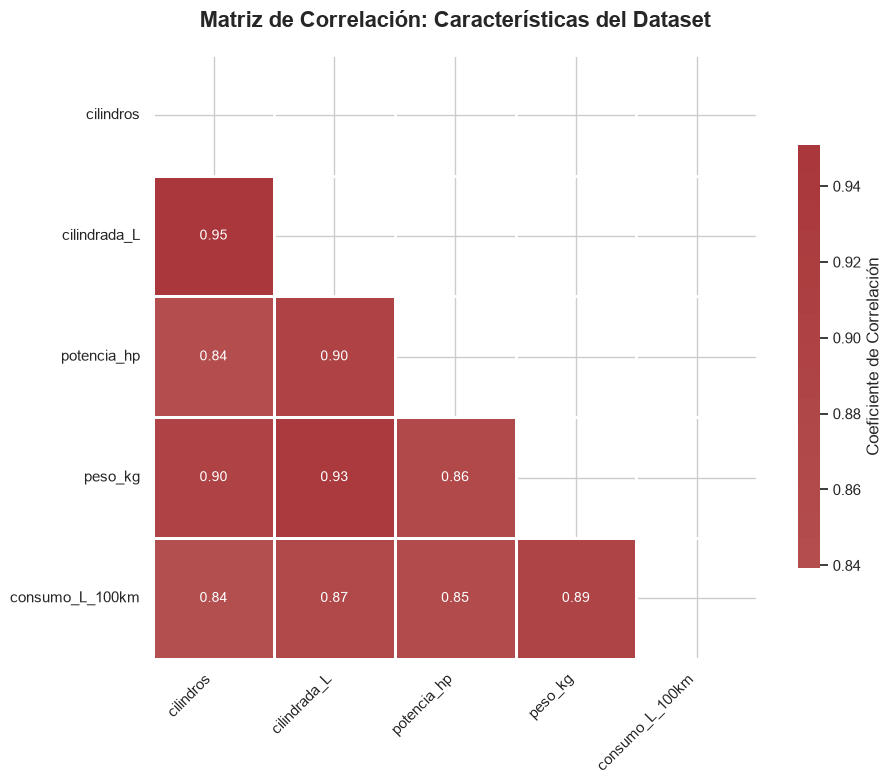

In [32]:

num = ['cilindros', 'cilindrada_L', 'potencia_hp',
       'peso_kg', 'consumo_L_100km']
corr = df[num].corr()
corr.round(2)

mask = np.triu(np.ones_like(corr, dtype=bool))
 
# 2. Ajustar el tamaño para que respire mejor
plt.figure(figsize=(10, 8))
 
# 3. Crear una paleta de colores divergente más suave y elegante
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# 4. Generar el heatmap con los nuevos ajustes
sns.heatmap(corr, 
            mask=mask, 
            annot=True, 
            fmt='.2f', 
            cmap=sns.color_palette("vlag", as_cmap=True),
            center=0,
            square=True, 
            linewidths=1,           # Líneas de separación un poco más gruesas
            linecolor='white',      # Color de separación en blanco para un look limpio
            cbar_kws={'shrink': .7, 'label': 'Coeficiente de Correlación'}, # Etiqueta en la barra derecha
            annot_kws={'size': 10, 'weight': '500'}) # Números más legibles
 
# 5. Título de la gráfica
plt.title('Matriz de Correlación: Características del Dataset', 
          fontsize=16, fontweight='bold', pad=20)
 
# Rotar etiquetas para que no se encimen
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(rotation=0, fontsize=11)
 
plt.tight_layout()
plt.show()

**✍️ Pregunta de análisis:** menciona **un par** de variables con `|r| > 0.9`, indica cuál
**eliminarías** y **justifica** por qué (2–3 líneas):

_(las variables mayor a 0.9 de acuerdo a la grafica son "cilindrada_L" y "cilindros", en lo personal eliminiaria la variable "cilindros_L", ya que esta demasiado asemejada en cantidad con la variable"cilindros", por lo que no habria una diferiencia notable en su cantidad)_

## Cierre  *(reporte, 0.5 pts)*
Muestra la forma final del dataset y sus columnas.

In [42]:
print('Dataset final:', df.shape)
print('Columnas:', list(df.columns))
df.head()

Dataset final: (398, 17)
Columnas: ['millas_galon', 'cilindros', 'cilindrada_pulg3', 'potencia_hp', 'peso_lb', 'aceleracion_s', 'año_modelo', 'origin', 'nombre', 'region', 'cilindrada_L', 'peso_kg', 'consumo_L_100km', 'marca', 'relacion_pot_peso', 'cilindrada_por_cil', 'antiguedad']


,millas_galon,cilindros,cilindrada_pulg3,potencia_hp,peso_lb,aceleracion_s,año_modelo,origin,nombre,region,cilindrada_L,peso_kg,consumo_L_100km,marca,relacion_pot_peso,cilindrada_por_cil,antiguedad
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu,EUA,5.03,1589.0,13.07,chevrolet,0.0818,0.629,12
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320,EUA,5.74,1675.0,15.68,buick,0.0985,0.718,12
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite,EUA,5.21,1559.0,13.07,plymouth,0.0962,0.651,12
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst,EUA,4.98,1557.0,14.70,amc,0.0963,0.622,12
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino,EUA,4.95,1564.0,13.84,ford,0.0895,0.619,12


---
### Rúbrica (10 pts)
| Parte | Criterio | Pts |
|---|---|---|
| 1 | Lee los 4 formatos correctamente y consolida (410 filas) | 2.0 |
| 2 | Elimina 12 duplicados e imputa faltantes con mediana | 2.0 |
| 3 | Mapeos de región y conversiones métricas correctas | 1.5 |
| 4 | Marca normalizada + feature propia con justificación | 2.0 |
| 5 | Heatmap correcto + par redundante bien justificado | 2.0 |
| Cierre | Notebook corre completo sin errores (*Run All*) | 0.5 |
| | **Total** | **10** |

<br>

> Se evalúa que el notebook **corra de principio a fin sin errores** y que las **respuestas de
> análisis** estén redactadas con criterio de ingeniería.
